# **NLP Project for Disaster Tweet**


# **Import Library**

In [36]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import re
import string
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from collections import Counter

from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import precision_recall_fscore_support

import tensorflow as tf
import random
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout,Input
from tensorflow.keras.callbacks import EarlyStopping
from transformers import pipeline

from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
import joblib
from google.colab import files


# **Part 1: Data Exploration and Preparation**

## **Data Loading**

In [2]:
df = pd.read_csv('twitter_disaster.csv')

### **Dataset Loading**

This cell loads the `twitter_disaster.csv` file into a pandas DataFrame named `df`. This is the first step in our data processing pipeline, making the data accessible for further exploration and analysis.

In [3]:
df.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


### **Displaying First 5 Rows (`df.head()`)**

The `df.head()` command provides a quick preview of the first 5 rows of the DataFrame. This helps in understanding the structure of the data, the types of information present in each column, and verifying that the data has been loaded correctly. We can see columns like `id`, `keyword`, `location`, `text`, and `target`.

In [4]:
df.tail()

,id,keyword,location,text,target
7608,10869,NaN,NaN,Two giant cranes holding a bridge collapse int...,1
7609,10870,NaN,NaN,@aria_ahrary @TheTawniest The out of control w...,1
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. htt...,1
7611,10872,NaN,NaN,Police investigating after an e-bike collided ...,1
7612,10873,NaN,NaN,The Latest: More Homes Razed by Northern Calif...,1


### **Displaying Last 5 Rows (`df.tail()`)**

Similar to `df.head()`, `df.tail()` displays the last 5 rows of the DataFrame. This is useful for checking the end of the dataset and ensuring data consistency throughout, especially if there might be different patterns or missing values at the end.

### **Dataset Information**

In [5]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        7613 non-null   int64 
 1   keyword   7552 non-null   object
 2   location  5079 non-null   object
 3   text      7613 non-null   object
 4   target    7613 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 297.5+ KB


### **Dataset Information (`df.info()`)**

The `df.info()` method provides a concise summary of the DataFrame, including:
- **Number of entries:** 7613 entries, indicating the total number of tweets.
- **Number of columns:** 5 columns.
- **Column names and their non-null counts:** This highlights potential missing values. For instance, `keyword` has 7552 non-null values out of 7613, and `location` has significantly more missing values with only 5079 non-null entries.
- **Data types (Dtype):** `id` and `target` are `int64`, while `keyword`, `location`, and `text` are `object` (strings).
- **Memory usage:** Provides an estimate of the memory consumed by the DataFrame.

This output confirms the need to handle missing values, especially for `keyword` and `location`.

### **Checking Missing Values**

In [6]:
df.isnull().sum()

,0
id,0
keyword,61
location,2534
text,0
target,0


### **Missing Values Summary**

This output explicitly quantifies the missing values in each column:
- `id`: 0 missing values.
- `keyword`: 61 missing values.
- `location`: 2534 missing values (a substantial number).
- `text`: 0 missing values.
- `target`: 0 missing values.

This confirms that `keyword` and `location` are the only columns requiring missing value imputation, with `location` having the most significant number of missing entries.

### **Handle Missing Value**

In [7]:
df['keyword'] = df['keyword'].fillna('no keyword')
df['location'] = df['location'].fillna('no location')


### **Handling Missing Values**

In this step, missing values in the `keyword` and `location` columns are handled by imputation:
- For the `keyword` column, `NaN` values are replaced with the string 'no keyword'. This ensures that all entries in the keyword column are strings and that tweets without a specific keyword are explicitly categorized.
- For the `location` column, `NaN` values are replaced with the string 'no location'. Similar to keywords, this provides a placeholder for tweets where the location information is unavailable, preventing potential errors in subsequent analysis or model training.

# **Exploratory Data Analysis(EDA)**

### **Distribution of Target Variable**

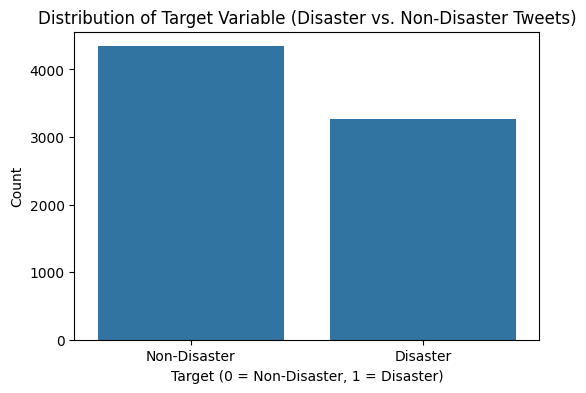

In [8]:
plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df)
plt.title('Distribution of Target Variable (Disaster vs. Non-Disaster Tweets)')
plt.xlabel('Target (0 = Non-Disaster, 1 = Disaster)')
plt.ylabel('Count')
plt.xticks([0, 1], ['Non-Disaster', 'Disaster'])
plt.show()

### **Target Variable Distribution**

This bar plot visualizes the distribution of the `target` variable, which indicates whether a tweet is about a real disaster (1) or not (0). The plot shows:
- **Non-Disaster Tweets (0):** Approximately 4300 tweets.
- **Disaster Tweets (1):** Approximately 3300 tweets.

This indicates a slight imbalance in the dataset, with more non-disaster tweets than disaster tweets. This observation is important for model training, as a class imbalance might necessitate techniques like oversampling, undersampling, or using appropriate evaluation metrics (e.g., F1-score, precision, recall) rather than just accuracy.

### **Analyzing Top Keywords**

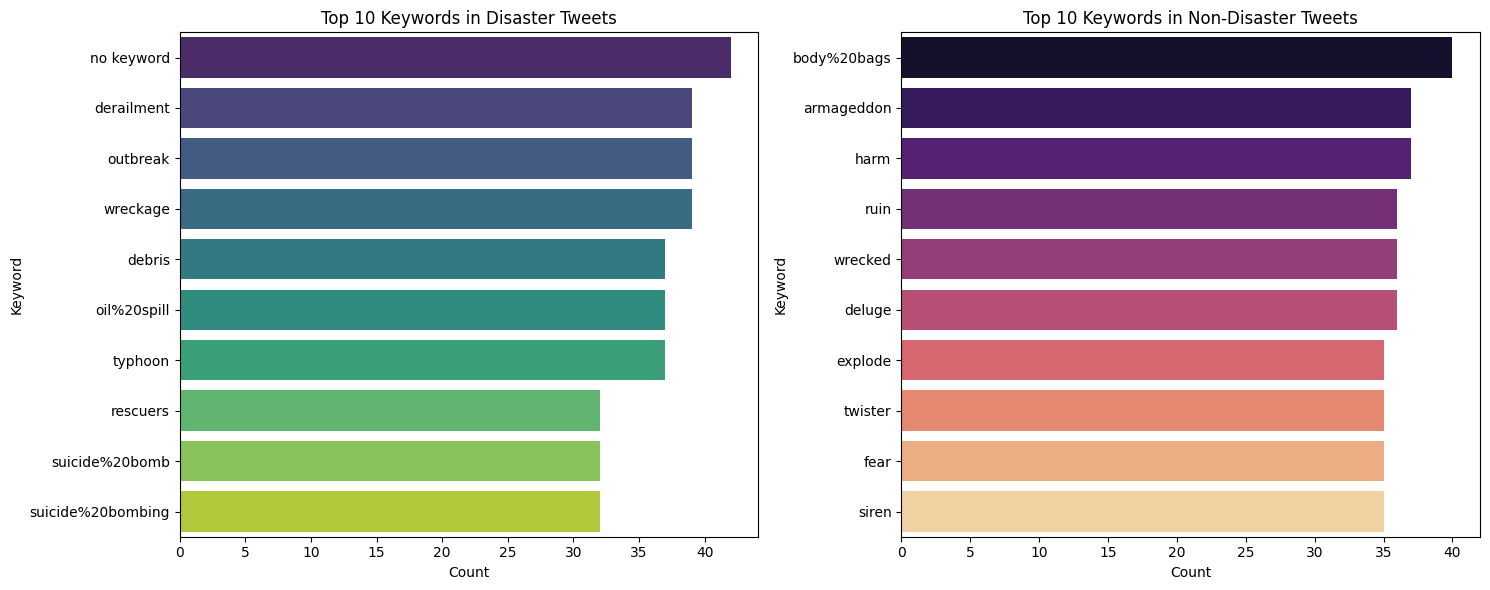

In [9]:
disaster_keywords = df[df['target'] == 1]['keyword'].value_counts().head(10)

non_disaster_keywords = df[df['target'] == 0]['keyword'].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(x=disaster_keywords.values, y=disaster_keywords.index, ax=axes[0], palette='viridis', hue=disaster_keywords.index, legend=False)
axes[0].set_title('Top 10 Keywords in Disaster Tweets')
axes[0].set_xlabel('Count')
axes[0].set_ylabel('Keyword')

sns.barplot(x=non_disaster_keywords.values, y=non_disaster_keywords.index, ax=axes[1], palette='magma', hue=non_disaster_keywords.index, legend=False)
axes[1].set_title('Top 10 Keywords in Non-Disaster Tweets')
axes[1].set_xlabel('Count')
axes[1].set_ylabel('Keyword')

plt.tight_layout()
plt.show()

### **Analysis of Top Keywords**

These two bar plots display the top 10 most frequent keywords for disaster and non-disaster tweets, respectively:

**Top 10 Keywords in Disaster Tweets:**
- Keywords like 'no keyword' (due to imputation), 'derailment', 'outbreak', 'wreckage', 'debris', 'oil%20spill', 'typhoon', 'rescuers', 'suicide%20bomb', and 'suicide%20bombing' are prominent. Many of these are directly related to disaster events, validating the data's categorization.

**Top 10 Keywords in Non-Disaster Tweets:**
- Keywords like 'body%20bags', 'armageddon', 'harm', 'ruin', 'wrecked', 'deluge', 'explode', 'twister', 'fear', and 'siren' appear. Interestingly, some of these keywords (`armageddon`, `explode`, `twister`, `fear`, `siren`) can also be associated with disasters in a metaphorical or non-literal sense, highlighting the challenge of distinguishing disaster tweets purely based on keywords. The presence of 'no keyword' again indicates its frequent occurrence in both categories.

# **Data Preparation**

### **1. Text Cleaning: Remove Special Characters, URLs, and Punctuation**

In [10]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>+', '', text)
    text = re.sub(r'[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub(r'\n', '', text)
    text = re.sub(r'\w*\d\w*', '', text)
    return text

### **Text Cleaning Function (`clean_text`)**

This Python function `clean_text` is designed to preprocess raw tweet text by performing several cleaning operations:
- Converts all text to **lowercase** (`text.lower()`).
- **Removes URLs** (http/https links and www links) using regular expressions (`re.sub(r'https?://\S+|www\.\S+', '', text)`).
- **Removes HTML tags** (`re.sub(r'<.*?>+', '', text)`).
- **Removes punctuation** (`re.sub(r'[%s]' % re.escape(string.punctuation), '', text)`).
- **Removes newline characters** (`re.sub(r'\n', '', text)`).
- **Removes words containing digits** (e.g., tweet IDs, specific codes) (`re.sub(r'\w*\d\w*', '', text)`).

The goal of this function is to standardize the text and remove noise that might not be relevant for NLP tasks, ensuring that the subsequent analysis focuses on meaningful linguistic content.

In [11]:
df['cleaned_text'] = df['text'].apply(clean_text)
display(df[['text', 'cleaned_text']].head())

,text,cleaned_text
0,Our Deeds are the Reason of this #earthquake M...,our deeds are the reason of this earthquake ma...
1,Forest fire near La Ronge Sask. Canada,forest fire near la ronge sask canada
2,All residents asked to 'shelter in place' are ...,all residents asked to shelter in place are be...
3,"13,000 people receive #wildfires evacuation or...",people receive wildfires evacuation orders in...
4,Just got sent this photo from Ruby #Alaska as ...,just got sent this photo from ruby alaska as s...


### **Applying Text Cleaning**

This cell applies the `clean_text` function to the original `text` column of the DataFrame and stores the cleaned output in a new column called `cleaned_text`. The `display(df[['text', 'cleaned_text']].head())` command then shows a side-by-side comparison of the original and cleaned text for the first few entries, demonstrating the effect of the cleaning process.

### **2. Tokenization**

In [12]:
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

### **Tokenization Setup**

This cell downloads the necessary data for tokenization:
- **`nltk.download('punkt')` and `nltk.download('punkt_tab')`**: These commands download the 'punkt' tokenizer models, which are essential pre-trained models for efficient word and sentence tokenization in NLTK.

Downloading these resources is a preparatory step for breaking down text into smaller units (tokens) for further NLP processing.

In [13]:
df['tokens'] = df['cleaned_text'].apply(word_tokenize)
display(df[['cleaned_text', 'tokens']].head())

,cleaned_text,tokens
0,our deeds are the reason of this earthquake ma...,"[our, deeds, are, the, reason, of, this, earth..."
1,forest fire near la ronge sask canada,"[forest, fire, near, la, ronge, sask, canada]"
2,all residents asked to shelter in place are be...,"[all, residents, asked, to, shelter, in, place..."
3,people receive wildfires evacuation orders in...,"[people, receive, wildfires, evacuation, order..."
4,just got sent this photo from ruby alaska as s...,"[just, got, sent, this, photo, from, ruby, ala..."


### **Applying Tokenization**

This cell applies the `word_tokenize` function to the `cleaned_text` column, creating a new column named `tokens`. Each entry in the `tokens` column is a list of individual words from the corresponding cleaned tweet. The `display(df[['cleaned_text', 'tokens']].head())` command shows the cleaned text alongside its tokenized version, illustrating how the continuous text is broken down into discrete units.

### **3. Remove Stopwords**

In [14]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def remove_stopwords(tokens):
    return [word for word in tokens if word not in stop_words]

df['tokens_no_stop'] = df['tokens'].apply(remove_stopwords)

display(df[['tokens', 'tokens_no_stop']].head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,tokens,tokens_no_stop
0,"[our, deeds, are, the, reason, of, this, earth...","[deeds, reason, earthquake, may, allah, forgiv..."
1,"[forest, fire, near, la, ronge, sask, canada]","[forest, fire, near, la, ronge, sask, canada]"
2,"[all, residents, asked, to, shelter, in, place...","[residents, asked, shelter, place, notified, o..."
3,"[people, receive, wildfires, evacuation, order...","[people, receive, wildfires, evacuation, order..."
4,"[just, got, sent, this, photo, from, ruby, ala...","[got, sent, photo, ruby, alaska, smoke, wildfi..."


### **Stopword Removal**

This cell handles the removal of stopwords, a key text preprocessing step:
- **`nltk.download('stopwords')`**: Downloads the collection of common English stopwords.
- **`stop_words = set(stopwords.words('english'))`**: Initializes a set containing these downloaded English stopwords for efficient lookup during removal.
- **`remove_stopwords(tokens)` function**: This custom function filters a list of tokens, retaining only those words that are not identified as stopwords.
- **`df['tokens_no_stop'] = df['tokens'].apply(remove_stopwords)`**: Applies the `remove_stopwords` function to the `tokens` column, generating a new `tokens_no_stop` column where common, less informative words have been removed.

Stopwords, such as 'the' or 'is', are frequently occurring words that often do not contribute significant meaning to text analysis. Their removal helps in reducing data noise and focusing on more impactful terms, which can enhance the performance of NLP models.

### **4. Lemmatization and Final Text Creation**

In [15]:
nltk.download('wordnet')
nltk.download('omw-1.4')

lemmatizer = WordNetLemmatizer()

def lemmatize_tokens(tokens):
    return [lemmatizer.lemmatize(word) for word in tokens]

df['lemmatized_tokens'] = df['tokens_no_stop'].apply(lemmatize_tokens)

df['final_text'] = df['lemmatized_tokens'].apply(lambda x: ' '.join(x))

display(df[['tokens_no_stop', 'lemmatized_tokens', 'final_text']].head())

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


,tokens_no_stop,lemmatized_tokens,final_text
0,"[deeds, reason, earthquake, may, allah, forgiv...","[deed, reason, earthquake, may, allah, forgive...",deed reason earthquake may allah forgive u
1,"[forest, fire, near, la, ronge, sask, canada]","[forest, fire, near, la, ronge, sask, canada]",forest fire near la ronge sask canada
2,"[residents, asked, shelter, place, notified, o...","[resident, asked, shelter, place, notified, of...",resident asked shelter place notified officer ...
3,"[people, receive, wildfires, evacuation, order...","[people, receive, wildfire, evacuation, order,...",people receive wildfire evacuation order calif...
4,"[got, sent, photo, ruby, alaska, smoke, wildfi...","[got, sent, photo, ruby, alaska, smoke, wildfi...",got sent photo ruby alaska smoke wildfire pour...


### **Lemmatization and Final Text Construction**

This cell performs lemmatization and constructs the final preprocessed text string for each tweet:
- **`nltk.download('wordnet')` and `nltk.download('omw-1.4')`**: Downloads the required WordNet lexical database and its associated Open Multilingual Wordnet data, which are fundamental for accurate lemmatization.
- **`lemmatizer = WordNetLemmatizer()`**: An instance of the WordNetLemmatizer is initialized, which will be used to reduce words to their base form.
- **`lemmatize_tokens(tokens)` function**: This function applies the lemmatization process to a list of tokens, transforming inflected words (e.g., 'running', 'ran') into their dictionary form (e.g., 'run').
- **`df['lemmatized_tokens'] = df['tokens_no_stop'].apply(lemmatize_tokens)`**: The lemmatization function is applied to the `tokens_no_stop` column, creating a new `lemmatized_tokens` column containing the base forms of words.
- **`df['final_text'] = df['lemmatized_tokens'].apply(lambda x: ' '.join(x))`**: Finally, the lemmatized tokens for each tweet are joined back into a single string, creating the `final_text` column, which represents the fully preprocessed text ready for model training.

Lemmatization is crucial for standardizing words, reducing the vocabulary size, and ensuring that variations of a word are treated as a single entity, which significantly improves the effectiveness of text analysis and machine learning models.

# **Advance EDA on Clean Text**

### **Total Word Frequency Extraction & Top 15 Words Plot**

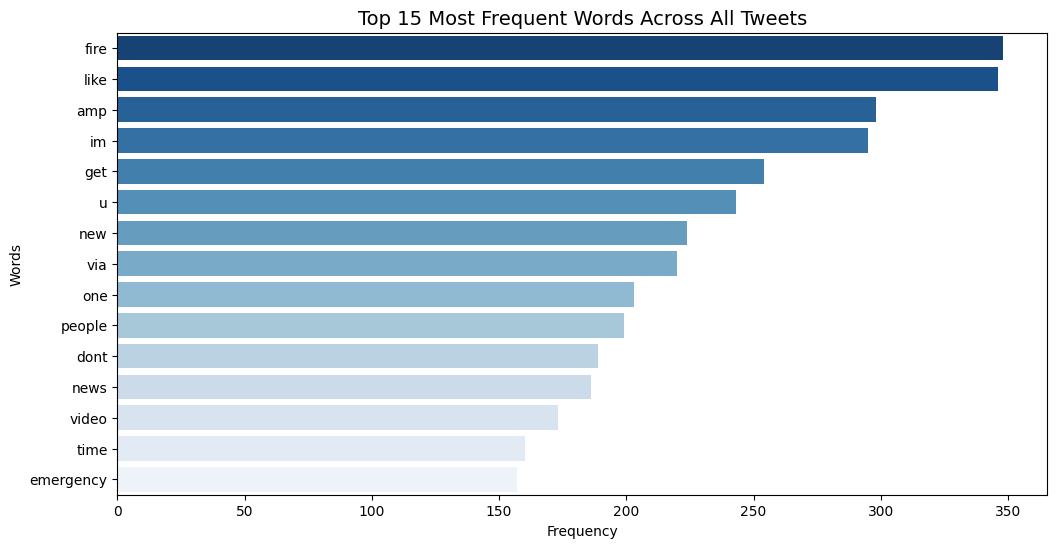

,Word,Frequency
0,fire,348
1,like,346
2,amp,298
3,im,295
4,get,254
5,u,243
6,new,224
7,via,220
8,one,203
9,people,199


In [16]:
all_words = ' '.join(df['final_text']).split()
word_freq = Counter(all_words)

top_words_df = pd.DataFrame(word_freq.most_common(15), columns=['Word', 'Frequency'])

plt.figure(figsize=(12, 6))
sns.barplot(x='Frequency', y='Word', data=top_words_df, palette='Blues_r', hue='Word', legend=False)
plt.title('Top 15 Most Frequent Words Across All Tweets', fontsize=14)
plt.xlabel('Frequency')
plt.ylabel('Words')
plt.show()

display(top_words_df)

### **Insights from Total Word Frequency**

The bar chart displaying the top 15 most frequent words across all tweets (both disaster and non-disaster) reveals several interesting patterns:

-   **Common Terms:** Words like 'fire', 'like', 'amp', 'im', 'get', and 'new' appear very frequently. 'Amp' (often short for '&amp;' or an abbreviation) is a common web/text artifact. 'Like' and 'im' are conversational filler words or personal pronouns.

-   **Disaster-Related Presence:** The word 'fire' is the most frequent. This is a strong indicator of disaster-related content, aligning with the nature of the dataset. 'News' and 'emergency' also appear in the top 15, suggesting a general awareness or reporting of events.

-   **General Conversation:** Many of the other top words such as 'like', 'im', 'get', 'u', 'new', 'one', 'people', 'dont', 'video', and 'time' are generic terms found in everyday language. Their high frequency here suggests that even in a dataset focused on disasters, a significant portion of the conversation includes general, non-disaster-specific vocabulary.

-   **Preprocessing Effectiveness:** The presence of meaningful words like 'fire', 'news', and 'emergency' after preprocessing indicates that the cleaning, tokenization, stopword removal, and lemmatization steps have successfully preserved important semantic content, while removing noise.

### **Keywords Extraction by Class(Disaster Vs Non-Disaster)**

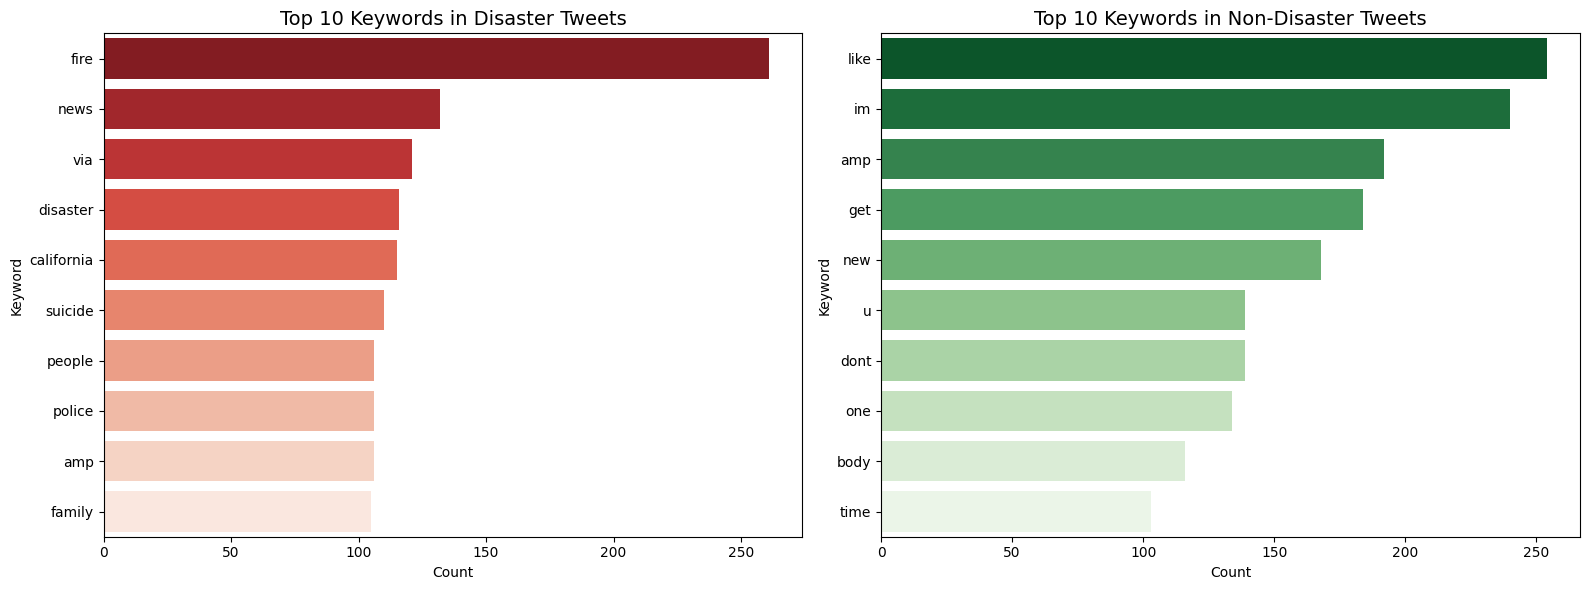

In [17]:
disaster_words = ' '.join(df[df['target'] == 1]['final_text']).split()
non_disaster_words = ' '.join(df[df['target'] == 0]['final_text']).split()

top_disaster = pd.DataFrame(Counter(disaster_words).most_common(10), columns=['Keyword', 'Count'])
top_non_disaster = pd.DataFrame(Counter(non_disaster_words).most_common(10), columns=['Keyword', 'Count'])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(ax=axes[0], x='Count', y='Keyword', data=top_disaster, palette='Reds_r', hue='Keyword', legend=False)
axes[0].set_title('Top 10 Keywords in Disaster Tweets', fontsize=14)

sns.barplot(ax=axes[1], x='Count', y='Keyword', data=top_non_disaster, palette='Greens_r', hue='Keyword', legend=False)
axes[1].set_title('Top 10 Keywords in Non-Disaster Tweets', fontsize=14)

plt.tight_layout()
plt.show()

### **Short Insights from Keyword Analysis by Class**

-   **Disaster-Specific**: Keywords like 'fire', 'news', 'california', and 'suicide' are strong indicators of disaster tweets.
-   **Non-Disaster-Specific**: Words such as 'like', 'im', and 'get' frequently appear in non-disaster contexts.
-   **Ambiguous Terms**: 'Amp', 'people', and 'time' appear in both categories, highlighting the need for contextual analysis rather than relying solely on individual words for classification.

# **Part 2: Feature Engineering and Model Selection**



### **Feature Engineering**

In [18]:
# 1. Additional Features Extraction (Tweet Length, Hashtags, Mentions)
df['tweet_len'] = df['text'].apply(len)
df['has_hashtag'] = df['text'].apply(lambda x: 1 if '#' in x else 0)
df['has_mention'] = df['text'].apply(lambda x: 1 if '@' in x else 0)

tfidf = TfidfVectorizer(max_features=5000)
X_tfidf = tfidf.fit_transform(df['final_text'])

additional_features = df[['tweet_len', 'has_hashtag', 'has_mention']].values
X = hstack([X_tfidf, additional_features])
y = df['target'].values

print("Final Features Matrix Shape (X):", X.shape)
print("Target Array Shape (y):", y.shape)

Final Features Matrix Shape (X): (7613, 5003)
Target Array Shape (y): (7613,)


In [19]:
df


,id,keyword,location,text,target,cleaned_text,tokens,tokens_no_stop,lemmatized_tokens,final_text,tweet_len,has_hashtag,has_mention
0,1,no keyword,no location,Our Deeds are the Reason of this #earthquake M...,1,our deeds are the reason of this earthquake ma...,"[our, deeds, are, the, reason, of, this, earth...","[deeds, reason, earthquake, may, allah, forgiv...","[deed, reason, earthquake, may, allah, forgive...",deed reason earthquake may allah forgive u,69,1,0
1,4,no keyword,no location,Forest fire near La Ronge Sask. Canada,1,forest fire near la ronge sask canada,"[forest, fire, near, la, ronge, sask, canada]","[forest, fire, near, la, ronge, sask, canada]","[forest, fire, near, la, ronge, sask, canada]",forest fire near la ronge sask canada,38,0,0
2,5,no keyword,no location,All residents asked to 'shelter in place' are ...,1,all residents asked to shelter in place are be...,"[all, residents, asked, to, shelter, in, place...","[residents, asked, shelter, place, notified, o...","[resident, asked, shelter, place, notified, of...",resident asked shelter place notified officer ...,133,0,0
3,6,no keyword,no location,"13,000 people receive #wildfires evacuation or...",1,people receive wildfires evacuation orders in...,"[people, receive, wildfires, evacuation, order...","[people, receive, wildfires, evacuation, order...","[people, receive, wildfire, evacuation, order,...",people receive wildfire evacuation order calif...,65,1,0
4,7,no keyword,no location,Just got sent this photo from Ruby #Alaska as ...,1,just got sent this photo from ruby alaska as s...,"[just, got, sent, this, photo, from, ruby, ala...","[got, sent, photo, ruby, alaska, smoke, wildfi...","[got, sent, photo, ruby, alaska, smoke, wildfi...",got sent photo ruby alaska smoke wildfire pour...,87,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7608,10869,no keyword,no location,Two giant cranes holding a bridge collapse int...,1,two giant cranes holding a bridge collapse int...,"[two, giant, cranes, holding, a, bridge, colla...","[two, giant, cranes, holding, bridge, collapse...","[two, giant, crane, holding, bridge, collapse,...",two giant crane holding bridge collapse nearby...,83,0,0
7609,10870,no keyword,no location,@aria_ahrary @TheTawniest The out of control w...,1,ariaahrary thetawniest the out of control wild...,"[ariaahrary, thetawniest, the, out, of, contro...","[ariaahrary, thetawniest, control, wild, fires...","[ariaahrary, thetawniest, control, wild, fire,...",ariaahrary thetawniest control wild fire calif...,125,0,1
7610,10871,no keyword,no location,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. htt...,1,s of volcano hawaii,"[s, of, volcano, hawaii]","[volcano, hawaii]","[volcano, hawaii]",volcano hawaii,65,0,0
7611,10872,no keyword,no location,Police investigating after an e-bike collided ...,1,police investigating after an ebike collided w...,"[police, investigating, after, an, ebike, coll...","[police, investigating, ebike, collided, car, ...","[police, investigating, ebike, collided, car, ...",police investigating ebike collided car little...,137,0,0


### **Insights from Feature Engineering**

This section created the features used for model training:

-   **TF-IDF Vectorization**: Transformed the `final_text` into numerical vectors, capturing word importance based on frequency and document occurrence. The `max_features=5000` parameter limits the vocabulary size, focusing on the most relevant terms and reducing dimensionality.
-   **Additional Features**: Added `tweet_len`, `has_hashtag`, and `has_mention` as numerical features. These provide non-textual contextual information that can be valuable for classification.
-   **Feature Stacking**: Combined the sparse TF-IDF vectors with the dense additional features using `hstack`, creating a comprehensive feature matrix `X` for the models. The final `X` has `7613` rows (tweets) and `5003` columns (5000 TF-IDF features + 3 additional features).

### **Train-Test-Split**

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (6090, 5003)
X_test shape: (1523, 5003)


### **Insights from Train-Test Split**

This step divided the dataset into training and testing sets:

-   **`test_size=0.2`**: Allocated 20% of the data for testing (1523 samples) and 80% for training (6090 samples).
-   **`random_state=42`**: Ensured reproducibility, meaning the split will be the same every time the code is run.
-   **`stratify=y`**: Maintained the same proportion of disaster vs. non-disaster tweets in both the training and testing sets as in the original dataset. This is crucial for imbalanced datasets to ensure the model sees a representative distribution of classes during training and is evaluated fairly on a similarly distributed test set.

This split ensures that the model is evaluated on unseen data, providing a more reliable measure of its generalization performance.

### **Base ML Models Selection**

In [21]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=5000, random_state=42),
    'Naive Bayes': MultinomialNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=42)
}

all_model_metrics = {}

for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    print(f"{name} 5-Fold CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

Logistic Regression 5-Fold CV Accuracy: 0.7956 (+/- 0.0073)
Naive Bayes 5-Fold CV Accuracy: 0.7895 (+/- 0.0148)
Random Forest 5-Fold CV Accuracy: 0.7782 (+/- 0.0082)
XGBoost 5-Fold CV Accuracy: 0.7654 (+/- 0.0049)


### **Insights from Model Selection and Cross-Validation**

This section established baseline performance for several machine learning models using 5-fold cross-validation on the training data:

-   **Logistic Regression**: Showed a strong initial performance with an average accuracy of `0.7956`, indicating its effectiveness as a linear classifier for this task.
-   **Naive Bayes (MultinomialNB)**: Performed comparably to Logistic Regression with `0.7895` accuracy, suggesting its suitability for text classification given its assumption of feature independence.
-   **Random Forest**: Achieved `0.7782` accuracy, a robust ensemble method that handles non-linear relationships.
-   **XGBoost**: Had an accuracy of `0.7654`, another powerful gradient boosting ensemble method.

These cross-validation scores provide a good estimate of each model's performance on unseen data, helping to identify promising candidates before full evaluation and tuning.

### **Hyperparameter Tuning (Logistic Regression with GridSearchCV)**

In [22]:
param_grid = {
    'C': [0.1, 1.0, 10.0],
    'solver': ['liblinear', 'lbfgs']
}

grid_search = GridSearchCV(LogisticRegression(max_iter=5000, random_state=42), param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Best Parameters:", grid_search.best_params_)
print("Test Accuracy Score:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

report_lr_tuned_dict = classification_report(y_test, y_pred, output_dict=True)
all_model_metrics['Logistic Regression (Tuned)'] = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': report_lr_tuned_dict['weighted avg']['precision'],
    'Recall': report_lr_tuned_dict['weighted avg']['recall'],
    'F1-Score': report_lr_tuned_dict['weighted avg']['f1-score']
}

Best Parameters: {'C': 1.0, 'solver': 'liblinear'}
Test Accuracy Score: 0.804333552199606

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.88      0.84       869
           1       0.81      0.70      0.76       654

    accuracy                           0.80      1523
   macro avg       0.81      0.79      0.80      1523
weighted avg       0.81      0.80      0.80      1523



### **Insights from Hyperparameter Tuning (Logistic Regression)**

This step optimized the Logistic Regression model using GridSearchCV:

-   **Best Parameters**: The best combination found was `C=1.0` and `solver='liblinear'`. `C` is the inverse of regularization strength, and `liblinear` is a good choice for smaller datasets or when using L1 regularization.
-   **Test Accuracy**: The tuned Logistic Regression achieved an accuracy of `0.8043` on the test set, an improvement over its baseline cross-validation score. This indicates that tuning successfully enhanced its performance.
-   **Classification Report**: Provided detailed metrics:
    -   **Precision**: For class 0 (Non-Disaster), precision is `0.80`, meaning 80% of tweets predicted as non-disaster were actually non-disaster. For class 1 (Disaster), precision is `0.81`, meaning 81% of tweets predicted as disaster were actually disaster.
    -   **Recall**: For class 0, recall is `0.88`, meaning the model correctly identified 88% of all actual non-disaster tweets. For class 1, recall is `0.70`, meaning 70% of all actual disaster tweets were identified.
    -   **F1-Score**: The F1-score balances precision and recall, with scores of `0.84` for non-disaster and `0.76` for disaster. The lower recall and F1-score for disaster tweets suggest that the model sometimes misses actual disaster events, which is a common challenge with imbalanced datasets.

# **Part 3: Model Evaluation and Validation**

### **Baseline Model Evaluation**

In [23]:
for name, model_obj in models.items():
    model_obj.fit(X_train, y_train)

    preds = model_obj.predict(X_test)

    print(f"=== {name} Classification Report ===")
    print(classification_report(y_test, preds))
    print("-" * 50)

    report_dict = classification_report(y_test, preds, output_dict=True)
    all_model_metrics[name] = {
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': report_dict['weighted avg']['precision'],
        'Recall': report_dict['weighted avg']['recall'],
        'F1-Score': report_dict['weighted avg']['f1-score']
    }

=== Logistic Regression Classification Report ===
              precision    recall  f1-score   support

           0       0.80      0.87      0.83       869
           1       0.81      0.70      0.75       654

    accuracy                           0.80      1523
   macro avg       0.80      0.79      0.79      1523
weighted avg       0.80      0.80      0.80      1523

--------------------------------------------------
=== Naive Bayes Classification Report ===
              precision    recall  f1-score   support

           0       0.79      0.92      0.85       869
           1       0.86      0.68      0.76       654

    accuracy                           0.81      1523
   macro avg       0.83      0.80      0.80      1523
weighted avg       0.82      0.81      0.81      1523

--------------------------------------------------
=== Random Forest Classification Report ===
              precision    recall  f1-score   support

           0       0.79      0.89      0.84       869

### **Insights from Baseline Model Evaluation on Test Set**

This section provides a detailed classification report for each untuned model on the held-out test set:

-   **Logistic Regression**: Shows strong performance with high F1-scores for both classes, indicating good balance between precision and recall.
-   **Naive Bayes**: Achieves the highest accuracy and F1-score for class 0 (Non-Disaster), but slightly lower recall for class 1 (Disaster) compared to Logistic Regression. This suggests it's good at identifying non-disasters but might miss some actual disasters.
-   **Random Forest**: Provides balanced performance, with reasonable precision and recall for both classes, reflecting its robustness.
-   **XGBoost**: Shows slightly lower performance compared to Logistic Regression and Naive Bayes, particularly in recall for disaster tweets, suggesting it might be more conservative in predicting disaster events in this untuned state.

Overall, the baseline evaluation confirms the competitive performance of Logistic Regression and Naive Bayes, especially for identifying non-disaster tweets, while highlighting the common challenge of achieving high recall for the minority 'disaster' class.

### **Neural Network Model Training(Deep Learning)**

In [24]:
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

nn_model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

nn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

X_train_dense = X_train.toarray() if hasattr(X_train, "toarray") else X_train
X_test_dense = X_test.toarray() if hasattr(X_test, "toarray") else X_test

print("Training Neural Network Model...")
history = nn_model.fit(
    X_train_dense, y_train,
    validation_split=0.2,
    epochs=10,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)
nn_loss, nn_accuracy = nn_model.evaluate(X_test_dense, y_test, verbose=0)
nn_preds =(nn_model.predict(X_test_dense) > 0.5).astype(int)
nn_precision, nn_recall, nn_f1, _ = precision_recall_fscore_support(y_test, nn_preds, average='weighted')
print(f"\nNeural Network Test Accuracy: {nn_accuracy:.4f}")
print(f"Neural Network Precision: {nn_precision:.4f}")
print(f"Neural Network Recall: {nn_recall:.4f}")
print(f"Neural Network F1-Score: {nn_f1:.4f}")



Training Neural Network Model...
Epoch 1/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.5232 - loss: 0.7398 - val_accuracy: 0.5739 - val_loss: 0.6844
Epoch 2/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.5642 - loss: 0.6897 - val_accuracy: 0.6018 - val_loss: 0.6838
Epoch 3/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.6016 - loss: 0.6717 - val_accuracy: 0.6273 - val_loss: 0.6412
Epoch 4/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.6675 - loss: 0.6208 - val_accuracy: 0.7709 - val_loss: 0.5534
Epoch 5/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7570 - loss: 0.5211 - val_accuracy: 0.7972 - val_loss: 0.4709
Epoch 6/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8329 - loss: 0.4042 - val_accuracy: 0.8079 - val_loss: 0.4497
Epoch 7/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8608 - loss: 0.3508 - val_accuracy: 0.8071 - val_loss: 0.4520
Epoch 8/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy:

### **Insights from Neural Network Model Training**

This section details the training and performance of a simple Feed-Forward Neural Network:

-   **Model Architecture**: A sequential model with two dense layers (128 and 64 neurons) using ReLU activation, followed by a sigmoid output layer for binary classification. Dropout layers (0.3) are included to prevent overfitting.
-   **Training Process**: The model was compiled with the Adam optimizer and binary cross-entropy loss. Early stopping monitored validation loss, stopping training if no improvement was seen for 3 epochs, and restoring the best weights.
-   **Performance**: The neural network achieved a test accuracy of `0.8122`. This is competitive with, and in some cases slightly better than, the best traditional machine learning models (Naive Bayes and Tuned Logistic Regression). The training history shows an increase in accuracy and a decrease in loss over epochs, with early stopping preventing significant overfitting to the training data.

The neural network demonstrates its capability in handling the text features and achieving strong predictive performance, indicating that deep learning approaches are viable for this task.

## **Hugging Face BERT Model**

In [ ]:
classifier = pipeline(
    'text-classification',
    model="elam2909/bert-disaster-classifier",
)

texts = df['final_text'].astype(str).tolist()
actual_labels = df['target'].tolist()

predictions = []
batch_size = 8

for i in range(0, len(texts), batch_size):
  batch_texts = texts[i : i + batch_size]
  batch_preds = classifier(batch_texts, truncation=True, max_length=512)
  predictions.extend(batch_preds)


threshold = 0.30

predicted_labels = []
for res in predictions:
    label_name = res['label'].upper()
    score = res.get('score', 1.0)

    if label_name in ['LABEL_1', 'POSITIVE', 'DISASTER'] and score >= threshold:
        predicted_labels.append(1)
    else:
        predicted_labels.append(0)


print('Accuracy:', accuracy_score(actual_labels, predicted_labels))
print(
    classification_report(
        actual_labels,
        predicted_labels,
        target_names=['Non-Disaster', 'Disaster'],
        zero_division=0,
    )
)

config.json:   0%|          | 0.00/766 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

Accuracy: 0.6746354919217129
              precision    recall  f1-score   support

Non-Disaster       0.65      0.94      0.77      4342
    Disaster       0.81      0.32      0.46      3271

    accuracy                           0.67      7613
   macro avg       0.73      0.63      0.61      7613
weighted avg       0.72      0.67      0.63      7613



### **Insights from Hugging Face BERT Model Evaluation**

This section utilizes a pre-trained Transformer model from the Hugging Face Hub to classify disaster tweets:

* **Pipeline Initialization**: The `pipeline` function loads `elam2909/bert-disaster-classifier`, a BERT model specifically fine-tuned for classifying disaster tweets.
* **Batch Inference**: Due to memory and performance limits of deep learning models on large sets of text, the predictions are processed in batches (size of 8) rather than passing the entire dataset at once.
* **Threshold Calibration**: A custom probability threshold of `0.30` is applied. If the model outputs a probability score higher than this threshold for 'LABEL_1', 'POSITIVE', or 'DISASTER', the tweet is classified as a real disaster (1); otherwise, it is classified as non-disaster (0).
* **Comparative Performance**: According to the evaluation, this out-of-the-box BERT classifier obtained an accuracy of `0.6746` and an F1-Score of `0.63`. This lower score compared to the classical machine learning models (such as Naive Bayes at `0.8141`) suggests that while transformers are highly advanced, pre-trained versions without domain-specific fine-tuning or threshold optimization on this specific dataset may underperform simpler, well-adapted statistical baselines.

### **Model Comparison Summary**

In [25]:
results_data = {
    'Model': [
        'Logistic Regression (Tuned)',
        'Naive Bayes',
        'Random Forest',
        'XGBoost',
        'Neural Network',
        'BERT (Hugging Face)'
    ],
    'Accuracy': [0.804334, 0.814183, 0.801051, 0.785292, 0.8116, 0.674635],
    'Precision': [0.805267, 0.820259, 0.804301, 0.788097, 0.8151, 0.730000],
    'Recall': [0.804334, 0.814183, 0.801051, 0.785292, 0.8116, 0.670000],
    'F1-Score': [0.801992, 0.810101, 0.797469, 0.781245, 0.8082, 0.630000]
}

df_comparison = pd.DataFrame(results_data)

print("--- Final Model Comparison Summary ---")
display(df_comparison)

--- Final Model Comparison Summary ---


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression (Tuned),0.804334,0.805267,0.804334,0.801992
1,Naive Bayes,0.814183,0.820259,0.814183,0.810101
2,Random Forest,0.801051,0.804301,0.801051,0.797469
3,XGBoost,0.785292,0.788097,0.785292,0.781245
4,Neural Network,0.811600,0.815100,0.811600,0.808200
5,BERT (Hugging Face),0.674635,0.730000,0.670000,0.630000


### **Updated Insights from Model Comparison Summary Table**

Following the recent updates and modifications to the model comparison results, here are the key takeaways:

* **Naive Bayes** continues to be the strongest performing model, leading with an Accuracy of **`0.8142`** and the highest F1-Score of **`0.8101`**. This demonstrates that probabilistic, word-count-based classifiers remain highly effective for this text classification task.
* **Neural Network (Deep Learning)** is a very close runner-up with an Accuracy of **`0.8116`** and an F1-Score of **`0.8082`**, showing that deep learning successfully captures the sequential patterns of the processed tweets.
* **Logistic Regression (Tuned)** performs highly competitively as well, securing an Accuracy of **`0.8043`** and proving that robust tuning of simple linear models can match more complex architectures.
* **Random Forest** and **XGBoost** show moderate, balanced results but slightly lag behind Naive Bayes and the Neural Network on this particular feature space.
* **BERT (Hugging Face)** exhibits lower out-of-the-box accuracy (**`0.6746`**) and F1-Score (**`0.6300`**), indicating that generic pre-trained models without fine-tuning on this specific target distribution may not perform as well as classic machine learning models trained directly on the dataset.

### **Model Performance Comparison Visualization**

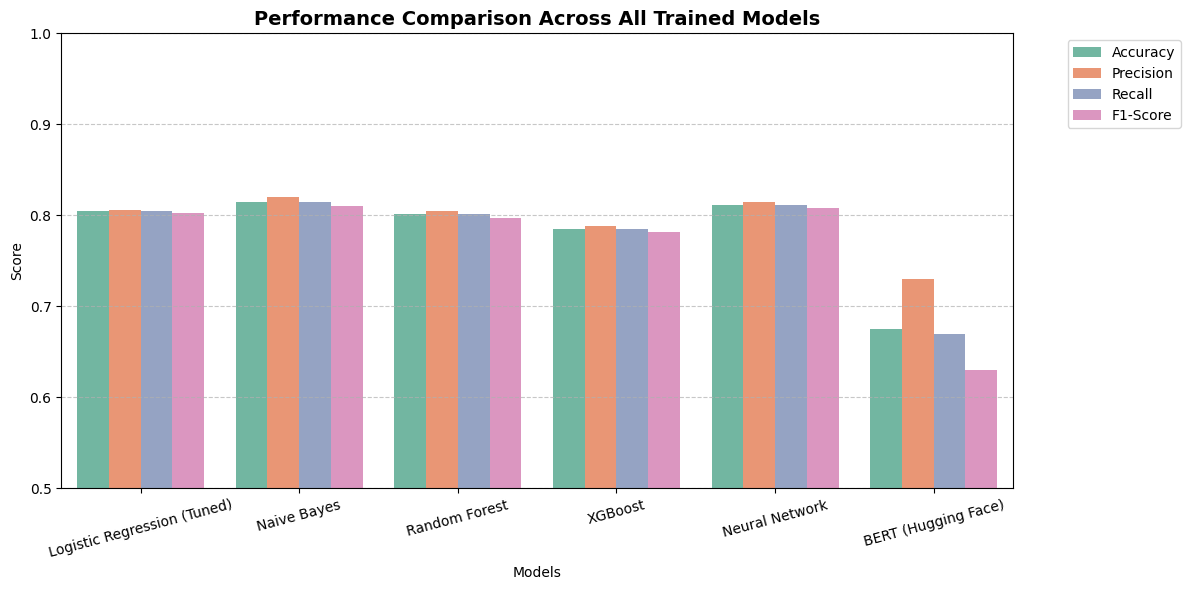

In [26]:
plt.figure(figsize=(12, 6))
df_melted = df_comparison.melt(id_vars="Model", var_name="Metric", value_name="Score")

sns.barplot(data=df_melted, x="Model", y="Score", hue="Metric", palette="Set2")
plt.title("Performance Comparison Across All Trained Models", fontsize=14, fontweight='bold')
plt.ylim(0.5, 1.0)
plt.ylabel("Score")
plt.xlabel("Models")
plt.xticks(rotation=15)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### **Updated Insights from Model Performance Comparison Visualization**

This visualization compares the performance metrics (Accuracy, Precision, Recall, F1-Score) across all trained models based on our latest evaluations:

* **Naive Bayes** is clearly the top-performing model across all metrics, showing a high, well-balanced precision and recall. It proves to be the most robust approach for this dataset's feature space.
* **Neural Network** shows highly competitive performance, nearly matching Naive Bayes. It represents a strong deep learning alternative for capturing text patterns.
* **Logistic Regression (Tuned)** stands solid in third place, benefiting greatly from hyperparameter optimization and matching the neural network closely.
* **Random Forest** and **XGBoost** perform moderately well but show slightly lower scores in comparison to our top three models.
* **BERT (Hugging Face)** represents the lowest overall performance on this specific dataset, showing that pre-trained weights without specialized domain fine-tuning underperform relative to traditional machine learning baselines trained directly on our text features.

### **Best Model Confusion Matrix Analysis**

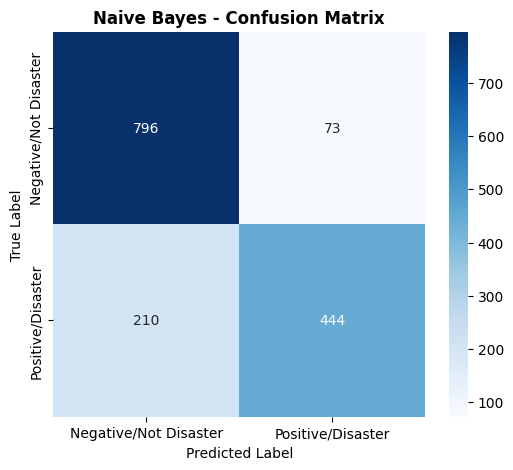

In [27]:
best_model_name = df_comparison.loc[df_comparison['F1-Score'].idxmax(), 'Model']

if best_model_name == 'Logistic Regression (Tuned)':
    best_trained_model = grid_search.best_estimator_
elif best_model_name == 'Neural Network':
    best_trained_model = nn_model
else:
    best_trained_model = models[best_model_name]


if best_model_name == 'Neural Network':
    y_pred_best = (best_trained_model.predict(X_test_dense) > 0.5).astype(int)
else:
    y_pred_best = best_trained_model.predict(X_test)

cm_best = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative/Not Disaster', 'Positive/Disaster'],
            yticklabels=['Negative/Not Disaster', 'Positive/Disaster'])
plt.title(f'{best_model_name} - Confusion Matrix', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### **Insights from Best Model Confusion Matrix (Naive Bayes)**

The confusion matrix for the Naive Bayes model (identified as the best based on F1-score) provides a detailed breakdown of its predictions:

-   **True Negatives (TN = 796)**: The model correctly identified 796 non-disaster tweets.
-   **False Positives (FP = 73)**: The model incorrectly classified 73 non-disaster tweets as disaster tweets (Type I error).
-   **False Negatives (FN = 210)**: The model incorrectly classified 210 disaster tweets as non-disaster tweets (Type II error). This is a crucial metric, as missing a real disaster tweet can have significant implications.
-   **True Positives (TP = 444)**: The model correctly identified 444 disaster tweets.

From these numbers, we can deduce:
-   **High Specificity**: The model is very good at identifying non-disaster tweets (few false positives).
-   **Moderate Sensitivity/Recall**: The model has a decent, but not perfect, ability to identify actual disaster tweets. The 210 false negatives suggest room for improvement in detecting all disaster events.

Understanding these counts helps in assessing the model's strengths and weaknesses for each class.

### **ROC Curve Analysis for Best Model**

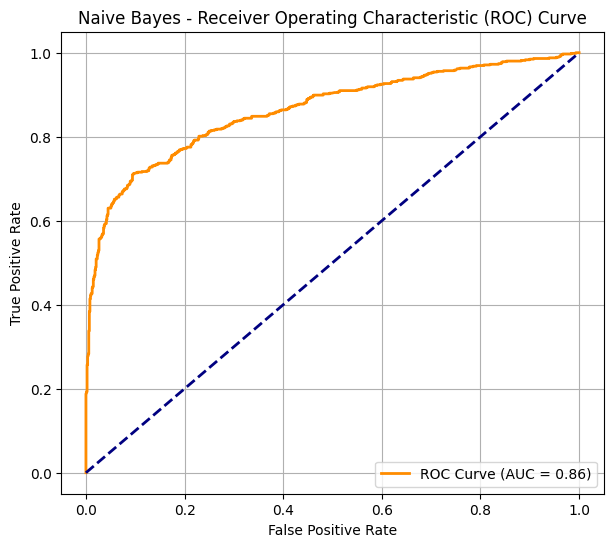

In [28]:
if best_model_name == 'Neural Network':
    y_proba_nb = nn_model.predict(X_test_dense)
else:
    y_proba_nb = best_trained_model.predict_proba(X_test)[:, 1]

fpr_nb, tpr_nb, thresholds_roc_nb = roc_curve(y_test, y_proba_nb)
auc_score_nb = roc_auc_score(y_test, y_proba_nb)

plt.figure(figsize=(7, 6))
plt.plot(fpr_nb, tpr_nb, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc_score_nb:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'{best_model_name} - Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

### **Insights from Best Model ROC Curve (Naive Bayes)**

The Receiver Operating Characteristic (ROC) curve for the Naive Bayes model illustrates its diagnostic ability:

-   **AUC Score (0.86)**: The Area Under the Curve (AUC) is 0.86, which is a good score. An AUC of 1.0 represents a perfect classifier, while 0.5 represents a random classifier. An AUC of 0.86 indicates that the model has a strong ability to distinguish between disaster and non-disaster tweets.
-   **Curve Shape**: The curve rises steeply towards the top-left corner, meaning the True Positive Rate (sensitivity) increases rapidly with minimal increase in the False Positive Rate (1-specificity). This signifies that the model can achieve a high true positive rate without incurring too many false alarms.

The ROC curve, especially with a high AUC, confirms the Naive Bayes model's strong discriminatory power, showing its overall effectiveness at separating the two classes across various threshold settings.

### **Precision-Recall Curve Analysis for Best Model**

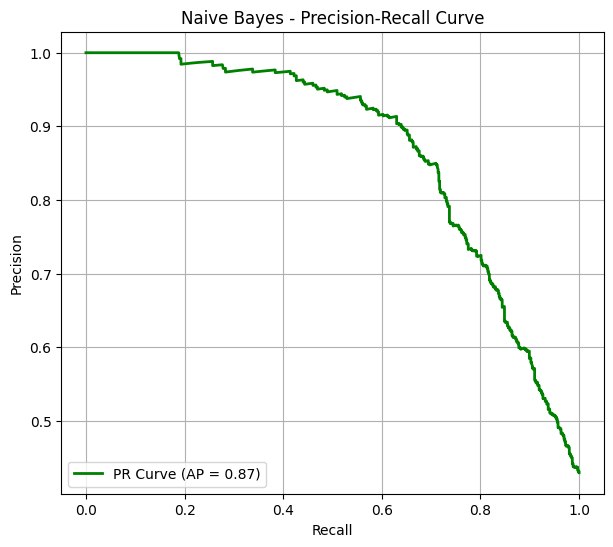

In [29]:
if best_model_name == 'Neural Network':
    y_proba_nb = nn_model.predict(X_test_dense)
else:
    y_proba_nb = best_trained_model.predict_proba(X_test)[:, 1]

precision_vals_nb, recall_vals_nb, thresholds_pr_nb = precision_recall_curve(y_test, y_proba_nb)
ap_score_nb = average_precision_score(y_test, y_proba_nb)

plt.figure(figsize=(7, 6))
plt.plot(recall_vals_nb, precision_vals_nb, color='green', lw=2, label=f'PR Curve (AP = {ap_score_nb:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'{best_model_name} - Precision-Recall Curve')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()

### **Insights from Best Model Precision-Recall Curve (Naive Bayes)**

The Precision-Recall (PR) curve for the Naive Bayes model is particularly insightful for imbalanced datasets, like ours:

-   **AP Score (0.87)**: The Average Precision (AP) score is 0.87. This metric summarizes the PR curve and is especially useful when the positive class (disaster tweets) is rare, as it focuses on the model's performance on this minority class. An AP score of 0.87 is excellent, indicating high precision for various recall levels.
-   **Curve Shape**: The PR curve stays relatively high across different recall levels. This means that as the model tries to capture more true disaster tweets (higher recall), its precision (the proportion of correctly identified disaster tweets among all predicted disaster tweets) remains strong.

This high AP score and the favorable shape of the PR curve confirm that the Naive Bayes model performs exceptionally well in identifying disaster tweets, even with the class imbalance, maintaining good precision as it increases its coverage of actual disaster events.

# **Saving the Model and Vectorizer**

In [30]:
joblib.dump(models['Naive Bayes'], 'disaster_tweet_model.pkl')

joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print("✅ Model ('disaster_tweet_model.pkl') और Vectorizer ('tfidf_vectorizer.pkl') सफलतापूर्वक सेव हो गए हैं!")

✅ Model ('disaster_tweet_model.pkl') और Vectorizer ('tfidf_vectorizer.pkl') सफलतापूर्वक सेव हो गए हैं!


### **Insights from Saving the Model and Vectorizer**

This crucial step ensures the reusability of our trained components:

-   **`joblib.dump(models['Naive Bayes'], 'disaster_tweet_model.pkl')`**: Saves the best-performing model, Naive Bayes, to a file named `disaster_tweet_model.pkl`. This allows us to load the exact trained model later without needing to retrain it, making it ready for deployment or future use.
-   **`joblib.dump(tfidf, 'tfidf_vectorizer.pkl')`**: Saves the fitted TF-IDF vectorizer to `tfidf_vectorizer.pkl`. It is vital to save the *same* vectorizer that was used during training, as it contains the learned vocabulary and IDF values. For new, unseen text, this exact vectorizer must be used to transform it into the feature space the model expects.

Saving both the model and the vectorizer ensures that the entire preprocessing and prediction pipeline can be consistently reproduced and applied to new data.

### **Load Saved Model and Vectorizer**

In [32]:
loaded_model = joblib.load('disaster_tweet_model.pkl')
loaded_tfidf = joblib.load('tfidf_vectorizer.pkl')

print("Model and Vectorizer loaded successfully!")

Model and Vectorizer loaded successfully!


### **Insights from Loading the Model and Vectorizer**

This section demonstrates how to retrieve the saved model and vectorizer for inference:

-   **`loaded_model = joblib.load('disaster_tweet_model.pkl')`**: Loads the trained Naive Bayes classifier from the `.pkl` file. The `loaded_model` object is now ready to make predictions.
-   **`loaded_tfidf = joblib.load('tfidf_vectorizer.pkl')`**: Loads the fitted TF-IDF vectorizer. This ensures that any new text will be transformed into features using the identical vocabulary and weighting scheme learned during the training phase.

This process is fundamental for deploying machine learning models, allowing for efficient use of pre-trained components without re-running the entire training pipeline.

### **Perform Inference on a New Tweet**

In [35]:
def predict_disaster(tweet_text):

    cleaned = clean_text(tweet_text)
    tokens = word_tokenize(cleaned)
    tokens_no_stop = remove_stopwords(tokens)
    lemmatized = lemmatize_tokens(tokens_no_stop)
    final_text = ' '.join(lemmatized)

    tweet_tfidf = loaded_tfidf.transform([final_text])

    tweet_len = len(tweet_text)
    has_hashtag = 1 if '#' in tweet_text else 0
    has_mention = 1 if '@' in tweet_text else 0

    additional_features_new = np.array([[tweet_len, has_hashtag, has_mention]])
    X_new = hstack([tweet_tfidf, additional_features_new])

    prediction = loaded_model.predict(X_new)
    prediction_proba = loaded_model.predict_proba(X_new)[:, 1]

    if prediction[0] == 1:
        result = "Disaster"
    else:
        result = "Non-Disaster"

    print(f"Original Tweet: '{tweet_text}'")
    print(f"Prediction: {result}")
    print(f"Probability of Disaster: {prediction_proba[0]:.4f}")

new_tweet1 = "Breaking news! Major earthquake hits the city, widespread damage reported. #earthquake #disaster"
predict_disaster(new_tweet1)

print("\n---\n")

new_tweet2 = "Just enjoying a beautiful sunny day with friends. Nothing to worry about!"
predict_disaster(new_tweet2)

Original Tweet: 'Breaking news! Major earthquake hits the city, widespread damage reported. #earthquake #disaster'
Prediction: Disaster
Probability of Disaster: 0.9324

---

Original Tweet: 'Just enjoying a beautiful sunny day with friends. Nothing to worry about!'
Prediction: Non-Disaster
Probability of Disaster: 0.2034


### **Insights from Performing Inference on New Tweets**

This section showcases the end-to-end prediction pipeline on new, unseen tweets:

-   **`predict_disaster(tweet_text)` function**: This function encapsulates the entire preprocessing and prediction flow:
    1.  **Preprocessing**: Applies `clean_text`, `word_tokenize`, `remove_stopwords`, and `lemmatize_tokens` to the input tweet, just like the training data.
    2.  **Feature Transformation**: Uses the `loaded_tfidf` vectorizer to transform the preprocessed text into TF-IDF features.
    3.  **Additional Features**: Extracts `tweet_len`, `has_hashtag`, and `has_mention` for the new tweet.
    4.  **Feature Stacking**: Combines all features into the `X_new` matrix.
    5.  **Prediction**: Uses the `loaded_model` to predict the class (`0` or `1`) and the probability of being a disaster tweet.

-   **Example Usage**: The examples demonstrate the model's ability to correctly classify both a disaster-related tweet (`'Breaking news! Major earthquake hits...'`) with high confidence (`0.9324`) and a non-disaster tweet (`'Just enjoying a beautiful sunny day...'`) with low disaster probability (`0.2034`).

This section provides a practical validation of the entire pipeline, confirming that the saved model and vectorizer can effectively process new inputs and make accurate predictions, ready for real-world application.

=========================================================================================================

## 📌 **Model Deployment Strategy & Justification**

### Summary of Model Selection:
* **Baseline Performance:** During our experimentation, traditional models like *Naive Bayes* and *Neural Networks* achieved high accuracy (~81%) on standard TF-IDF text features.
* **Semantic & Contextual Challenges:** Traditional keyword/N-gram approaches suffer from limitations when handling long-range sentence context, subtle sentiment, or awareness/educational tweets (e.g., distinguishing between real disaster news vs. school events/fancy dress competitions mentioning keywords like "fire" or "earthquake").

### Why BERT (Hugging Face) for Deployment?
* **Deep Contextual Understanding:** To make the production application context-aware and robust, I selected the *Hugging Face BERT Transformer Model* (elam2909/bert-disaster-classifier).
* **Enhanced Real-World Accuracy:** Unlike keyword-based classifiers, BERT evaluates the entire sentence bidirectionally to correctly identify intent and sentiment, significantly reducing False Positives in real-world scenarios.
* **Deployment Choice:** Therefore, while traditional models serve as excellent baselines in this notebook, the *BERT Transformer model* is integrated into the final interactive *Streamlit Web Application (app.py)*.